# Experiment 6: A simple neural network

A 2-4-1 sigmoid network trained on XOR by backpropagation, in NumPy only.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10})

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)
HIDDEN, SEED, EPOCHS = 4, 1, 20000

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

## A single linear unit cannot represent XOR
Train a 2-1 sigmoid unit (no hidden layer) for comparison.

In [2]:
rng = np.random.default_rng(SEED)
w, b = rng.normal(0, 1, (2, 1)), np.zeros((1, 1))
for _ in range(EPOCHS):
    o = sigmoid(X @ w + b)
    d = (o - y) * o * (1 - o)
    w -= 0.5 * X.T @ d; b -= 0.5 * d.sum(0, keepdims=True)
single_out = sigmoid(X @ w + b).ravel()
single_mse = float(np.mean((single_out - y.ravel())**2))
print('single unit outputs:', single_out.round(3), ' MSE', round(single_mse, 4))

single unit outputs: [0.5 0.5 0.5 0.5]  MSE 0.25


## Two-layer network: forward pass, backpropagation, gradient descent

In [3]:
def train_xor(lr, epochs=EPOCHS, seed=SEED, hidden=HIDDEN, zero_init=False):
    rng = np.random.default_rng(seed)
    if zero_init:
        W1, W2 = np.zeros((2, hidden)), np.zeros((hidden, 1))
    else:
        W1, W2 = rng.normal(0, 1, (2, hidden)), rng.normal(0, 1, (hidden, 1))
    b1, b2 = np.zeros((1, hidden)), np.zeros((1, 1))
    loss = np.empty(epochs)
    for e in range(epochs):
        h = sigmoid(X @ W1 + b1)                    # forward
        o = sigmoid(h @ W2 + b2)
        loss[e] = np.mean((o - y)**2)
        do = (o - y) * o * (1 - o)                  # output delta
        dh = (do @ W2.T) * h * (1 - h)              # hidden delta
        W2 -= lr * h.T @ do; b2 -= lr * do.sum(0, keepdims=True)
        W1 -= lr * X.T @ dh; b1 -= lr * dh.sum(0, keepdims=True)
    return (W1, b1, W2, b2), loss

def predict(params, Xq):
    W1, b1, W2, b2 = params
    return sigmoid(sigmoid(Xq @ W1 + b1) @ W2 + b2)

lr =  0.05: final MSE 2.31e-03, all outputs correct True, converged False, MSE<1e-2 at epoch 10851


lr =   0.5: final MSE 1.11e-04, all outputs correct True, converged True, MSE<1e-2 at epoch 1086


lr =   2.0: final MSE 2.46e-05, all outputs correct True, converged True, MSE<1e-2 at epoch 272


lr =  10.0: final MSE 5.81e-06, all outputs correct True, converged True, MSE<1e-2 at epoch 70


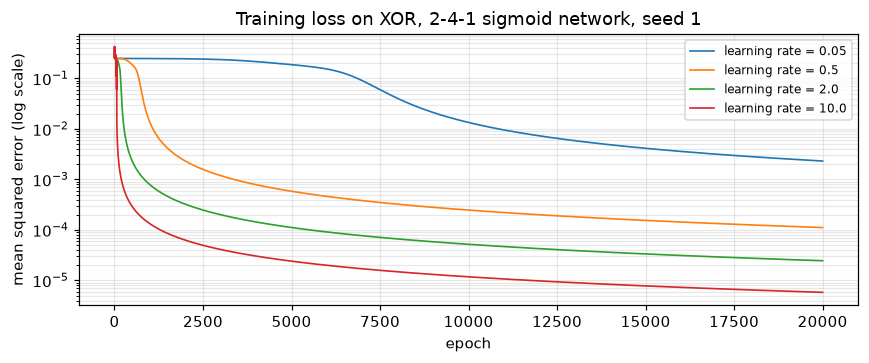

In [4]:
LRS = [0.05, 0.5, 2.0, 10.0]
runs, rows = {}, []
for lr in LRS:
    params, loss = train_xor(lr)
    out = predict(params, X).ravel()
    correct = bool(np.all((out > 0.5) == y.ravel().astype(bool)))
    converged = bool(correct and loss[-1] < 1e-3)
    below = np.where(loss < 1e-2)[0]
    rows.append(dict(lr=lr, final_mse=float(loss[-1]), correct=correct, converged=converged,
                     epoch_mse_below_1e2=int(below[0]) if below.size else None,
                     outputs=out.round(3).tolist()))
    runs[lr] = (params, loss)
    print(f'lr = {lr:>5}: final MSE {loss[-1]:.2e}, all outputs correct {correct}, '
          f'converged {converged}, MSE<1e-2 at epoch {rows[-1]["epoch_mse_below_1e2"]}')

fig, ax = plt.subplots(figsize=(8, 3.4))
for lr in LRS:
    ax.semilogy(runs[lr][1], lw=1.1, label=f'learning rate = {lr}')
ax.set_xlabel('epoch'); ax.set_ylabel('mean squared error (log scale)')
ax.set_title('Training loss on XOR, 2-4-1 sigmoid network, seed 1')
ax.grid(True, which='both', alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('figs/fig6_1_loss.png')

best learning rate 10.0 predictions [0.002 0.998 0.998 0.003]


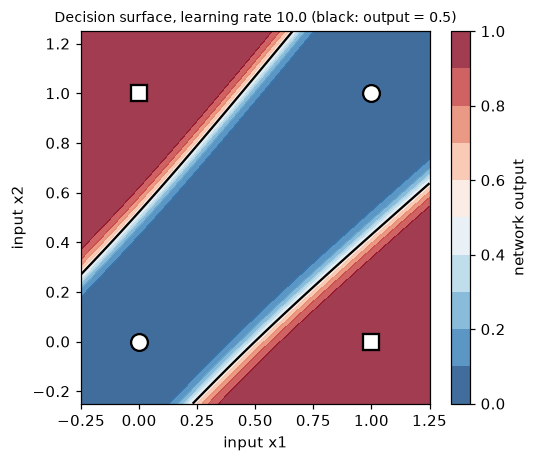

In [5]:
best = min(rows, key=lambda r: r['final_mse'])['lr']
params = runs[best][0]
pred = predict(params, X).ravel()
print('best learning rate', best, 'predictions', pred.round(3))

gx, gy = np.meshgrid(np.linspace(-0.25, 1.25, 300), np.linspace(-0.25, 1.25, 300))
Z = predict(params, np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(5, 4.3))
cf = ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.8)
ax.contour(gx, gy, Z, levels=[0.5], colors='k', linewidths=1.5)
for (a, b_), t in zip(X, y.ravel()):
    ax.plot(a, b_, 's' if t else 'o', ms=11, mfc='white', mec='k', mew=1.5)
fig.colorbar(cf, ax=ax, label='network output')
ax.set_xlabel('input x1'); ax.set_ylabel('input x2')
ax.set_title(f'Decision surface, learning rate {best} (black: output = 0.5)', fontsize=9)
fig.tight_layout(); fig.savefig('figs/fig6_2_decision_boundary.png')

## Zero initialisation (viva question 2)

In [6]:
pz, lz = train_xor(2.0, zero_init=True)
W1z = pz[0]
print('zero init: final MSE', round(float(lz[-1]), 4), '| outputs', predict(pz, X).ravel().round(3))
print('hidden-unit weight columns identical:', bool(np.allclose(W1z, W1z[:, :1])))

zero init: final MSE 0.25 | outputs [0.5 0.5 0.5 0.5]
hidden-unit weight columns identical: True


In [7]:
with open('obs.json', 'w') as fh:
    json.dump(dict(shape='2-4-1', activations='sigmoid (hidden and output)', seed=SEED, epochs=EPOCHS,
                   loss='mean squared error', rows=rows, best_lr=best, best_pred=pred.round(3).tolist(),
                   single_unit=dict(outputs=single_out.round(3).tolist(), mse=single_mse),
                   zero_init=dict(mse=float(lz[-1]), outputs=predict(pz, X).ravel().round(3).tolist())),
              fh, indent=1)